 HRXP - calculates PCI and SAXS images for an XFEL beamline

 © Copyright 2022 by Thomas Kluge (t.kluge@hzdr.de)

 This file is part of HRXP, the Hibef ReLaX XFEL Propagator.

 HRXP is free software: you can redistribute it and/or modify
 it under the terms of the GNU General Public License as published by
 the Free Software Foundation, either version 3 of the License, or
 any later version.

 HRXP is distributed in the hope that it will be useful,
 but WITHOUT ANY WARRANTY; without even the implied warranty of
 MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.  See the
 GNU General Public License for more details.

 You should have received a copy of the GNU General Public License
 along with HRXP.  If not, see <http://www.gnu.org/licenses/>.


## Comments by Lingen:
- https://rafael-fuente.github.io/simulating-diffraction-patterns-with-the-angular-spectrum-method-and-python.html
- There are two propagators from target to the detector in the code;
- One propagator is called lorentz_propagate_to_position(), the other is called spectral_propagate_to_position() which is more general without Fresnel approximation. They work equally in some cases, but with different spatial resolutions at the detector plane;
- The lorentz propagator solves the Fresnel integral via FFT method. It is limited by the approximations of the Fresnel and Fraunhofer regimes. It is also limited by the requirement of a different grid scale than the aperture figure. It currently works for single frequency; 
- In case of Lorentz propagator, the spatial resolution or grid scale at the detector plane  = Z * $\lambda$ / L ,where Z is the distance from target to detector and $\lambda$ is XFEL wavelength, L is the length of the Matrix at the target plane. The momentum q resolution = 2 * pi / L; In q space, the first peak (or the distance of the the peaks) for the wire target should be at q = 2 * pi /d where d is the target diameter, or at the grid point N_peak = L /d; Thus in real space, the first peak for the wire target should be Z * $\lambda$ / L*N_peak = Z * $\lambda$ / L * L /d = Z * $\lambda$/d. Thus N_peaks = L/d/2 is the numbers of the peaks corresponding to the wire diameter. In default, SAXS uses the Lorentz propagator. For a 1 $\mu$m thick target, the q distance between each peak corresponding to the thickness is ~0.006e nm$^{-1}$. In experiment, our Jungfrau SAXS typically meaures the q ranging from 0.05 to 0.4 nm$^{-1}$ which corresponds to 100s of peaks and with q resolution of ~ 0.004 nm$^{-1}$ which is at the limit to resolve maximum 1 $\mu$m structure. Instead, our SAXS is able to resolve the spatial structure with 10s nm structure. The higher q, the smaller spatial structure can be resolved.  
- The angular spectra propagtor spectral_propagate_to_position() solves the Helmhotz equation exactly. So no Fresnel approximation. It uses the same scale that the aperture figure (or has the same spatial resolution with that in the target plane), and it should work for the beam with XFEL bandwidth. In default, PCI uses the angular spectra propagtor. Since the Zyla pixel size of PCI is 10 to 100 times smaller than the SAXS Jungfrau detector (6.5$\mu$m /magnification VS 75 $\mu$m), and it is put further away compared to the SAXS (6.3 m VS 1.6m), PCI resolves much smaller q compared to SAXS. And thus PCI's spatial resolution is much smaller (~1$\mu$m VS 10s nm for SAXS) which resolve macro changes of the target density.
- The angular spectra propagtor requires big Matrix for a big FoV since th spatial resolution is the same as in the target plane;
- Lorentz propagator should work better for SAXS in terms of q space, while Spectrum propagator should work better for PCI interm of real space;
- Phase wrapping seems NOT matter much. 
- The reason why the angular spectrum method is not used in all cases, is that for large propagation distances it burdens a larger computation time than the other methods. Depending on the specific problem, any memory size of computers is too small to solve the problem.
- Far field condition:  Z * $\lambda$ >> $\rho^2$, or Fr =  $\rho^2$/(Z * $\lambda$) << 1 indicating that k * $\rho^2$ /2Z << $\pi$, where $\rho$ is the Field of view on the target plane. Thus the change of the phase is quite small in the Fresnel propagation and can be neglected for the SAXS detector which can't resolve such small phase change. So for the Lorentz propagator solving the Fressnel integral equation (FFT is only relevant for the field distribution at the target plane and the phase change at the detector plane can be ignored), the spatial distribution of the field has very weak dependence of Z (the distance from target to the detector), corresponding to SAXS which is indeed far field approximation. For example with the wire SAXS scattering calculaiton here (mainly in horizontal condition, so it is 1D case), the maximum phase change is ~ 2 * $\pi$ * Fr = 2 * $\pi$ / [Z * $\lambda$/ $\rho^2$ ]= 2* $\pi$ / [ 1.3m * 0.152nm /(10nm * 10nm * 2048) ] =  2* $\pi$ / 964 << $\pi$;
- For the far field approximation or Fraunhofer diffraction, since it is mainly relevant for the field distribution at the target plane and the phase change at the detector plane can be ignored for SAXS, solving the Fresnel integral with FFT then is equivalent to the FFT of the electron density that electron density is linear to the phase shift when propagating throught the thin target. Thus, the wave diffractive is simply equivalent to the small angle X-ray scattering (considerign the light as a wave or particle surprising gives the same physics picture and results).  
- For a single pixel size in this calculation ,  we can define the Fresnel number: Fr = (pixel size)^2/(wavelength * propagation distance) to judge if the case is far (Fr << 1, phase change = Fr 2 * $\pi$ ~ 1, Fraunhofer diffraction) or near field (Fr >> 1). In our case Fr = 75nm * 75nm/(0.1512nm)/6.31m =5 * 1e-7 for single pixel at the aixs. However , for 2D case with diffraction, then we have maxiumum Fresnel number 2048 * 2048 * Fr ~ 2.4 for 6.3 m. So the far field condition is not satisfied anymore. Thus the diffraction pattern depends on the detector postion a lot. Phase constrast imaging (PCI) resolves the very small change of the phase of q, and thus bigger spatial resolution. 
- In experiment, assuming an overall magnification of M = (5.26m + 0.1m) / 0.1m = 53.6, then an effective Fresnel number of Fr = ((6.5um/7.5)/53.6)^2 / ((5.26m/53.6) * 0.1512 nm) = Fr / 53.6 = 1.7 e-5. Reconstructions work best if we are in the regime Fr = 1e-4 ... 1e-3. During the commissioning #2621, we were at 1e-5, which is too small.
- Why 3D matrix is needed? Could we switch it to 2D?
- It seems the SAXS signal is affected a lot by the XFEL beam divergence. A smaller focus (in the focused beam case) would allow for greater details to be visible. It is worth to check the divergent effect.
- In Lorentz propagator, the spatial resolution on the detector is  $\Delta x_1$ = Z * $\lambda$ / L and q resolution is $\Delta q_1$ = 2 * $\pi$ / L ;
- In Angular spectrum propagator, the spatial resolution on the detector is  $\Delta x_2$ = L/N and q resolution is $\Delta q_2$ = 2 * $\pi$ / ($N * \Delta x_1$) = 2 * $\pi$ *L /(N* Z * $\lambda$);
- First peak position for Angular spectrum propagator is at Z * $\lambda$/d where d is the target thickness.



# Usage example

In [1]:
#includes
#%matplotlib inline
import PCI
import LightPipes as LP
import pickle
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LogNorm
from PIL import Image
import scipy.ndimage as ndimage
from scipy import interpolate
import rossendorfer_farbenliste as rofl

PCI successfully compiled. You can get more help by typing 'PCI.help()'


  This program comes with ABSOLUTELY NO WARRANTY; for details type `show w'.
  This is free software, and you are welcome to redistribute it
  under certain conditions; type `show c' for details.


In [2]:
#load experimental pattern
with open("./SAXSData/profiles_cleaned_p3129_r0528.pickle", "rb") as pf:
    data = pickle.load(pf)
for i, o in enumerate(data):
    data[i] = np.nan_to_num(data[i], nan = 0)
lineout_GT_528 = np.concatenate((np.flip(data[1])[:-1], data[2]))
q_GT_528 = np.concatenate((np.flip(-data[0])[:-1], data[0]))


with open("./SAXSData/profiles_cleaned_p3129_r0546.pickle", "rb") as pf:
    data = pickle.load(pf)
for i, o in enumerate(data):
    data[i] = np.nan_to_num(data[i], nan = 0)
lineout_GT_546 = np.concatenate((np.flip(data[1])[:-1], data[2]))
q_GT_546 = np.concatenate((np.flip(-data[0])[:-1], data[0]))


with open("./SAXSData/profiles_cleaned_p3129_r0534.pickle", "rb") as pf:
    data = pickle.load(pf)
for i, o in enumerate(data):
    data[i] = np.nan_to_num(data[i], nan = 0)
lineout_GT_534 = np.concatenate((np.flip(data[1])[:-1], data[2]))
q_GT_534 = np.concatenate((np.flip(-data[0])[:-1], data[0]))

In [3]:
N = 8192  # number of pixels (adjust as needed)
N_SAXS = 4096*2

XFEL_photon_energy = 8.2*PCI.keV # in unit of keV
wavelength_nm = 2*np.pi/(5.06773076*XFEL_photon_energy) # in unit of nm
wavelength_LP = wavelength_nm*LP.nm # in unit of m
#FWHM_PCI = 33*PCI.um #fwhm = waist*1.177410023
#FWHM_PCI = 0.50546212287*PCI.um #point soruce, corresponding to 33um FWHM on the target plane 

#FWHM_PCI = 12.4*PCI.um #collimated fwhm = waist*1.177410023 --> waist = 10.53159*PCI.um
#FWHM_PCI = 1.354*PCI.um # point fwhm = waist*1.177410023 --> waist = 10.53159*PCI.um


#FWHM_LP = FWHM_PCI*LP.um #point soruce, corresponding to 33um FWHM on the target plane 

pixel_size_PCI = 8*PCI.nm #in unit of nm
pixel_size_LP = pixel_size_PCI*LP.nm #in unit of m
size_LP = N*pixel_size_LP #in unit of m

Z_target_PCI = 0.25*PCI.m

#Z_detector_PCI = 0.0027089904*PCI.m #the distance make the resolution is 10nm
#Z_detector_PCI = 0.15238070981*PCI.m #the distance make the resolution is 75nm
Z_detector_PCI = 1.31*PCI.m #distance from TCC to Outerwall (SAXS JF detector)
#Z_detector_PCI = 1.35*PCI.m # A possible distance from TCC to SAXS JF detector
#Z_detector_PCI = 6.31*PCI.m #distance from TCC to PCI Zyla detector 

Z_source_detector_PCI = Z_target_PCI + Z_detector_PCI
Z_detector_LP = Z_detector_PCI*LP.nm # in unit of m

r_PCI = 5*PCI.um # wire radius in nm
d_LP = 2*r_PCI*LP.nm # wire diameter in m

x_peak =  Z_detector_LP * wavelength_LP/d_LP/LP.um # theoretic calculaiton of the first peak position correspondting to the target thickness in unit of um

k_saxs = 2*np.pi/N/pixel_size_PCI # k resolution
extent_saxs = [-k_saxs*N/2, k_saxs*N/2, -k_saxs*N/2, k_saxs*N/2]
extent_saxs2 = [-0.3, 0.3, -0.3, 0.3]
#k_space = np.linspace(-2048,2047,N)*2*np.pi/N/pixel_size_PCI # k sapce in unit of nm^-1

q_max = np.pi/(pixel_size_PCI)
k_space = np.linspace(-q_max, q_max, N)
k_space_IJ = np.linspace(-q_max, q_max, 4096)
#extent_saxs_IJ = [-k_saxs*N/2, k_saxs*N/2, -k_saxs*N/2, k_saxs*N/2]

In [4]:
k_saxs

9.587379924285257e-05

In [5]:
(k_space[4096+1]-k_space[4096])

np.float64(9.588550401629092e-05)

In [6]:
1000*k_space[4096+1]

np.float64(0.14382825602443639)

In [7]:
1e3*(k_space[4096+1]-k_space[4096])

np.float64(0.09588550401629092)

In [8]:
SAXS_theory = 1/k_space**(3)/3e8

The offset is 0.0 um


<>:114: SyntaxWarning: invalid escape sequence '\m'
<>:115: SyntaxWarning: invalid escape sequence '\m'
<>:117: SyntaxWarning: invalid escape sequence '\m'
<>:150: SyntaxWarning: invalid escape sequence '\m'
<>:176: SyntaxWarning: invalid escape sequence '\m'
<>:114: SyntaxWarning: invalid escape sequence '\m'
<>:115: SyntaxWarning: invalid escape sequence '\m'
<>:117: SyntaxWarning: invalid escape sequence '\m'
<>:150: SyntaxWarning: invalid escape sequence '\m'
<>:176: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1889382/784861762.py:114: SyntaxWarning: invalid escape sequence '\m'
  f"Radius={r_PCI/1e3:0.1f} $\mu$m\n"
/tmp/ipykernel_1889382/784861762.py:115: SyntaxWarning: invalid escape sequence '\m'
  f"Offset={offset/1e3:0.1f} $\mu$m\n"
/tmp/ipykernel_1889382/784861762.py:117: SyntaxWarning: invalid escape sequence '\m'
  f"Source XFEL FWHM = {FWHM_PCIs[0]/1e3:0.3f} $\mu$m\n"
/tmp/ipykernel_1889382/784861762.py:150: SyntaxWarning: invalid escape sequence '\m'
  plt.

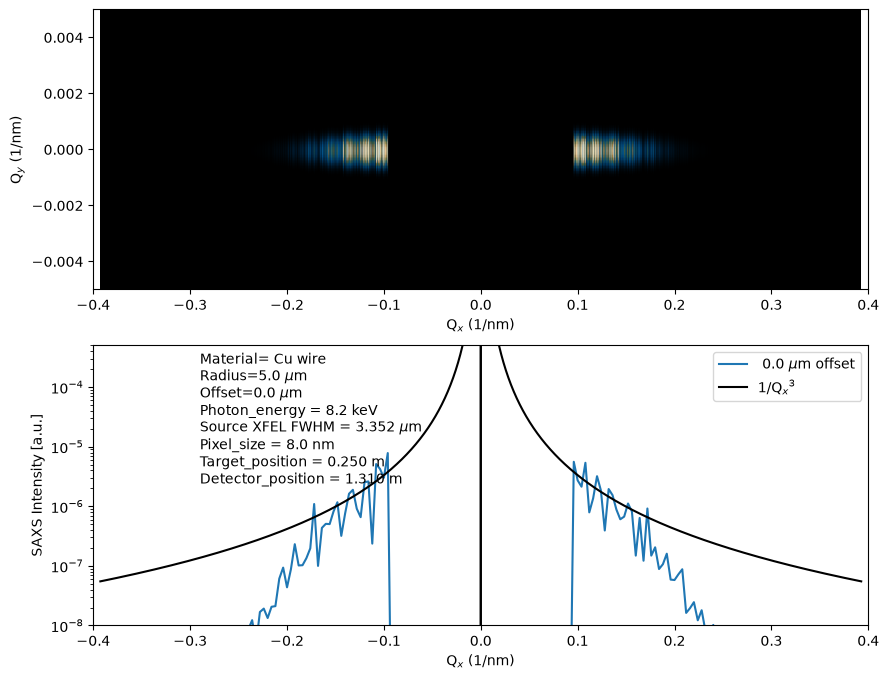

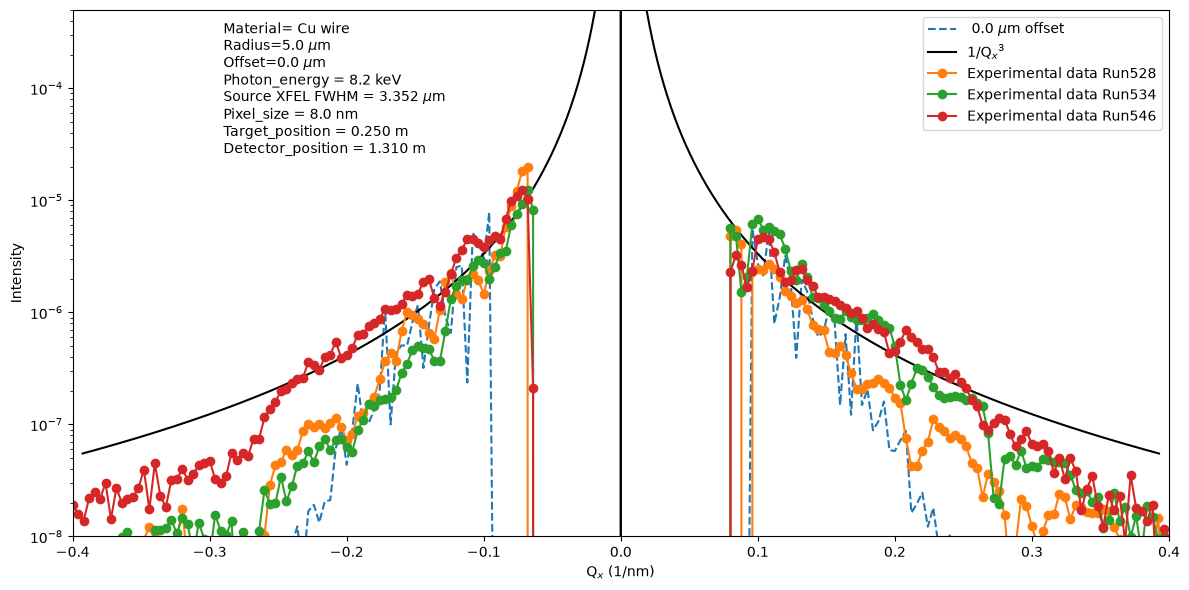

In [9]:
#Detector_type = ["SAXS", "PCI"] 

#FWHM_PCIs = np.array([1.354*PCI.um, 12.4*PCI.um]) #XFEL FWHM 12.4 um on target

waist = 6

FWHM_PCIs = np.array([2.84672*1.177410023*PCI.um, 4.22666*1.177410023*PCI.um]) #XFEL FWHM 6 um on target

#FWHM_PCIs = np.array([2.17449*1.177410023*PCI.um, 5.53332*1.177410023*PCI.um]) #XFEL FWHM 7 um on target

#FWHM_PCIs = np.array([1.83955*1.177410023*PCI.um, 6.54082*1.177410023*PCI.um]) #XFEL FWHM 8 um on target

#FWHM_PCIs = np.array([1.61022*1.177410023*PCI.um, 7.47237*1.177410023*PCI.um]) #XFEL FWHM 9 um on target

#FWHM_PCIs = np.array([1.43741*1.177410023*PCI.um, 8.3707*1.177410023*PCI.um]) #XFEL FWHM 10 um on target

#FWHM_PCIs = np.array([1.30055*1.177410023*PCI.um, 9.25157*1.177410023*PCI.um]) #XFEL FWHM 11 um on target

#FWHM_PCIs = np.array([1.18867*1.177410023*PCI.um, 10.1223*1.177410023*PCI.um]) #XFEL FWHM 12 um on target
divergent = 1
FWHM_LP = FWHM_PCIs*LP.um #point soruce, corresponding to 33um FWHM on the target plane 

#offsets = np.arange(-10,10.2,0.4)*PCI.um #fwhm = waist*1.177410023
#offsets = np.arange(-0.2,0.4,0.2)*PCI.um #fwhm = waist*1.177410023
#offsets = np.arange(9,10.3,0.5)*PCI.um #fwhm = waist*1.177410023
offsets = np.arange(0,0.2,0.2)*PCI.um #fwhm = waist*1.177410023

SAXS_asymmetry = np.ones((offsets.size,3))

for count, offset in enumerate(offsets):
    
    print(f'The offset is {offset/1e3} um')
    
    target = PCI.wire(
        "wire",                 # arbitrary but unique label
        photon_Energy = XFEL_photon_energy, # in unit of keV
        radius = r_PCI,            # radius in nm
        material = PCI.Cu,
        #position=[0,0,Z_target_PCI],
        #position=[0,-4*PCI.um,Z_target_PCI],
        position=[0,offset,Z_target_PCI],
        #voxel_size=100*PCI.nm, # in case of 33um XFEL
        #voxel_size=50*PCI.nm, # in case of 12.4um XFEL, large voxel_size makes the SAXS droppes faster, not physical.
        voxel_size=20*PCI.nm, # seems to be best with 20nm for the interpolation compare with scattering theory
        voxel_number = 1000
    )


    # define an XFEl beam and make it aware of the target
    XFEL = PCI.gaussian_XFEL(
        waist = FWHM_PCIs[0]/1.177410023, #fwhm = waist*1.177410023
        pixel_number = N,
        pixel_size = pixel_size_PCI,
        photon_energy = XFEL_photon_energy,
        photon_energy_bandwidth = 0*PCI.eV,               # default is 0
        photon_energy_bandwidth_sample_width = 0*PCI.eV
    )

    # define a detector
    zyla = PCI.jungfrau(
        "Zyla",            # unique identifer
        category = "SAXS",  # PCI or SAXS
        XFEL=XFEL,         # pixel sizes and numbers are set to those of the XFEL, required for now
        #position=[0,0,6.31*PCI.m]       # position relative to XFEL focus
        position=[0,0,Z_source_detector_PCI]       # 75 nm resolution on the detector plane
    )
    
    #bl = PCI.Beamline()
    #bl.add_target(target)
    #bl.add_XFEL(XFEL)
    #bl.add_detector(zyla)
    #bl.propagate_XFEL_to(detector = zyla)
    
    
    
    
    #intensity_bt = XFEL.intensity_beforetarget
    #phase_bt = XFEL.phase_beforetarget 

    #intensity_at = XFEL.intensity_aftertarget 
    #phase_at = XFEL.phase_aftertarget 


    #new_pixel_size = XFEL.new_pixel_size
    #new_pixel_size2 = XFEL._pixel_size
    #x_plot = XFEL.new_x_plot
    #print (f'new pixel size is {new_pixel_size:0.3f} um') 
    #print (f'new pixel size is {new_pixel_size2:0.3f} nm') 
    #print (f'new pixel range is {x_plot} um')

    if abs(offset)>0.05:
        SAXS_divergent_im = Image.open(f'./Data_{pixel_size_PCI:0.0f}nm/{waist:0.0f}um/DivSAXS_Offset{offset/1e3:0.2f}um.tif')   
    else:
        SAXS_divergent_im = Image.open(f'./Data_{pixel_size_PCI:0.0f}nm/{waist:0.0f}um/DivSAXS_Offset0.00um.tif')          
        
    SAXS_divergent = np.array(SAXS_divergent_im) 
    SAXS_divergent[int(N_SAXS/2-1000):int(N_SAXS/2+1000),int(N_SAXS/2-1000):int(N_SAXS/2+1000)] = 1e-12
    
    SAXS_divergent2 = np.array(SAXS_divergent_im)
        
        
    interp_SAXS_divergent = interpolate.interp1d(k_space, np.mean(SAXS_divergent[int(N/2-1):int(N/2+1),:],axis=0), fill_value = "extrapolate")
    lineout_SAXS_divergent = interp_SAXS_divergent(q_GT_528)    
    
    lineout_SAXS2 = np.mean(SAXS_divergent2[int(N/2-1):int(N/2+1),:],axis=0)
    
    SAXS_asymmetry[count,0] = offset
    #SAXS_asymmetry[count,1] = np.sum(lineout_SAXS2[0:int(lineout_SAXS2.shape[0]/2)-50])
    #SAXS_asymmetry[count,2] = np.sum(lineout_SAXS2[int(lineout_SAXS2.shape[0]/2)+50:lineout_SAXS2.shape[0]])
    SAXS_asymmetry[count,1] = np.sum(lineout_SAXS2[0:int(lineout_SAXS2.shape[0]/2)-1040])
    SAXS_asymmetry[count,2] = np.sum(lineout_SAXS2[int(lineout_SAXS2.shape[0]/2)+1040:lineout_SAXS2.shape[0]])
    
    InputParameters = ("Material= Cu wire\n"
                       f"Radius={r_PCI/1e3:0.1f} $\mu$m\n" 
                       f"Offset={offset/1e3:0.1f} $\mu$m\n" 
                       f"Photon_energy = {XFEL_photon_energy:0.1f} keV\n"                   
                       f"Source XFEL FWHM = {FWHM_PCIs[0]/1e3:0.3f} $\mu$m\n"
                       #f"Target XFEL FWHM size = {XFEL.FWHM_target:0.1f} $\mu$m\n"
                       f"Pixel_size = {pixel_size_PCI} nm\n"
                       f"Target_position = {Z_target_PCI/1e9:0.3f} m\n"
                       f"Detector_position = {Z_detector_PCI/1e9:0.3f} m\n")

    
    fig = plt.figure(figsize=(10, 8),facecolor="w")

    plt.subplot(2, 1, 1)
    #plt.imshow(intensity_detector, cmap='inferno')
    #plt.imshow(IJ_SAXS, cmap='inferno', extent=extent_saxs, norm=LogNorm(),aspect=1)
    #plt.imshow(SAXS_divergent, cmap='inferno', extent=extent_saxs, norm=LogNorm(),aspect='auto')
    plt.imshow(SAXS_divergent,  cmap=rofl.cmap(), extent=extent_saxs, aspect='auto')
    #plt.imshow(SAXS_divergent, cmap='inferno', extent=extent_saxs2, aspect='auto')
    #plt.colorbar(orientation="horizontal")
    #plt.colorbar()
    #plt.xlim(-size_LP*1e6/2,size_LP*1e6/2)
    plt.xlim(-0.4,0.4)
    plt.ylim(-0.015,0.015)
    plt.ylim(-0.005,0.005)
    #plt.clim(1e-9,5e-2) 
    plt.clim(1e-11,0.5e-7)
    #plt.clim(2e-10,np.max(SAXS_divergent))
    #plt.clim(5e-10, 3e-2)
    #plt.clim(1e-10, 10e-2)
    plt.xlabel(f"Q$_x$ (1/nm)")
    plt.ylabel(f"Q$_y$ (1/nm)")
    #plt.title('Divergent SAXS on detector')
    
    plt.subplot(2, 1, 2)
    #plt.semilogy(q_GT_528,lineout_SAXS_divergent/np.max(lineout_SAXS_divergent)*2,'--',label=f'Simulated SAXS with 0 $\mu$m wire center offset')
    #plt.semilogy(q_GT_528,lineout_SAXS_divergent/np.max(lineout_SAXS_divergent)*2,'-',label=f' {offset/1e3:0.1f} $\mu$m offset')
    plt.semilogy(q_GT_528,lineout_SAXS_divergent/0.02,'-',label=f' {offset/1e3:0.1f} $\mu$m offset')
    plt.semilogy(k_space, SAXS_theory,'k',label=f'1/Q$_x$$^3$')
    plt.semilogy(-k_space, SAXS_theory,'k')
    #plt.semilogy(q_GT_528,lineout_GT_528/np.max(lineout_GT_528)/50e3,'o-',label='Exp. Run528')
    #plt.semilogy(q_GT_534,lineout_GT_534/np.max(lineout_GT_534)/80e3,'o-',label='Exp. Run534')
    #plt.semilogy(q_GT_546,lineout_GT_546/np.max(lineout_GT_546)/80e3,'o-',label='Exp. Run546')
    plt.xlim(-0.4,0.4)
    plt.ylim(1e-8,5e-4)
    #plt.plot(x_pci,np.mean(intensity_detector_pci[2048-1:2048+1,:],axis=0)/np.max(intensity_detector_pci),'--',label='Python:PCI on detector')
    #plt.plot(x_pci,np.mean(I4_Fresnel[2048-1:2048+1,:],axis=0)/np.max(I4_Fresnel),'--',label='Lightpipes Fresnel')
    #plt.plot(x_pci,np.mean(I4_Forvar[2048-1:2048+1,:],axis=0)/np.max(I4_Forvar),'--',label='Lightpipes Forvar')
    #plt.axvline(x = x_peak, color = 'k', label = 'First peak for target thickness')
    #plt.axvline(x = 2*np.pi/10e3, color = 'k', label = 'First peak for target thickness')
    plt.text(-0.29, 4e-4, InputParameters, ha='left', va='top',rotation=0, wrap=True)
    plt.legend(loc = "upper right")
    plt.xlabel(f"Q$_x$ (1/nm)")
    plt.ylabel("SAXS Intensity [a.u.]")    
    
    plt.savefig(f'./Movie/{waist:0.0f}um/{count:02d}DivSAXS_offset{offset/1e3:0.1f}um_T{waist:0.0f}um_Pix{pixel_size_PCI}nm'
                f'_D{Z_target_PCI/1e9:0.2f}_{Z_detector_PCI/1e9:0.2f}m.png',dpi=200,bbox_inches='tight') 
    #plt.savefig(f'./Movie/Movie2_mask/{count:02d}LinearDivSAXS_offset{offset/1e3:0.1f}um_T{12:0.0f}um_Pix{pixel_size_PCI}nm'
    #            f'_D{Z_target_PCI/1e9:0.2f}_{Z_detector_PCI/1e9:0.2f}m.png',dpi=200,bbox_inches='tight') 

    fig = plt.figure(figsize=(12, 6),facecolor="w")
    #plt.semilogy(q_GT_528,lineout_IJ_SAXS/np.max(lineout_IJ_SAXS),'-',label='ImageJ:SAXS on detector')
    #plt.semilogy(q_GT_528,lineout_SAXS_divergent/np.max(lineout_SAXS_divergent),'--',label=f'Divergent SAXS on detector Source XFEL FWHM = {FWHM_PCIs[0]/1e3:0.3f} $\mu$m')
    plt.semilogy(q_GT_528,lineout_SAXS_divergent/0.02,'--',label=f' {offset/1e3:0.1f} $\mu$m offset')
    plt.semilogy(k_space, SAXS_theory,'k',label=f'1/Q$_x$$^3$')
    plt.semilogy(-k_space, SAXS_theory,'k')
    plt.semilogy(q_GT_528,lineout_GT_528/np.max(lineout_GT_528)/50e3,'o-',label='Experimental data Run528')
    plt.semilogy(q_GT_534,lineout_GT_534/np.max(lineout_GT_534)/80e3,'o-',label='Experimental data Run534')
    plt.semilogy(q_GT_546,lineout_GT_546/np.max(lineout_GT_546)/80e3,'o-',label='Experimental data Run546')
    plt.xlim(-0.4,0.4)
    plt.ylim(1e-8,5e-4)
    #plt.plot(x_pci,np.mean(intensity_detector_pci[2048-1:2048+1,:],axis=0)/np.max(intensity_detector_pci),'--',label='Python:PCI on detector')
    #plt.plot(x_pci,np.mean(I4_Fresnel[2048-1:2048+1,:],axis=0)/np.max(I4_Fresnel),'--',label='Lightpipes Fresnel')
    #plt.plot(x_pci,np.mean(I4_Forvar[2048-1:2048+1,:],axis=0)/np.max(I4_Forvar),'--',label='Lightpipes Forvar')
    #plt.axvline(x = x_peak, color = 'k', label = 'First peak for target thickness')
    #plt.axvline(x = 2*np.pi/10e3, color = 'k', label = 'First peak for target thickness')
    plt.text(-0.29, 4e-4, InputParameters, ha='left', va='top',rotation=0, wrap=True)
    plt.legend(loc = "upper right")
    plt.xlabel(f"Q$_x$ (1/nm)")
    plt.ylabel("Intensity")
    #plt.title('Python: Phase map')
    plt.tight_layout()
    plt.savefig(f'./Movie/{waist:0.0f}um/1D/Divoffset{offset/1e3:0.1f}um_{count:02d}DivSAXS_T{waist:0.0f}um_Pix{pixel_size_PCI}nm'
                f'_D{Z_target_PCI/1e9:0.2f}_{Z_detector_PCI/1e9:0.2f}m.png',dpi=200,bbox_inches='tight')   
#np.savetxt(f'DivSAXS_asymmetry_Mark1300_{waist:0.0f}um.dat', SAXS_asymmetry)  



In [10]:
offset

np.float64(0.0)

In [11]:
lineout_SAXS2.shape[0]

8192

<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:52: SyntaxWarning: invalid escape sequence '\m'
<>:65: SyntaxWarning: invalid escape sequence '\m'
<>:67: SyntaxWarning: invalid escape sequence '\m'
<>:81: SyntaxWarning: invalid escape sequence '\m'
<>:30: SyntaxWarning: invalid escape sequence '\m'
<>:52: SyntaxWarning: invalid escape sequence '\m'
<>:65: SyntaxWarning: invalid escape sequence '\m'
<>:67: SyntaxWarning: invalid escape sequence '\m'
<>:81: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1889382/1515723136.py:30: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel(f"wire offset [$\mu$m]")
/tmp/ipykernel_1889382/1515723136.py:52: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel(f"wire offset [$\mu$m]")
/tmp/ipykernel_1889382/1515723136.py:65: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(SAXS_asymmetry[:,0]/1e3,SAXS_asymmetry[:,1]/(SAXS_asymmetry[:,1]+SAXS_asymmetry[:,2]),'o-',label=f'Lingen:left/(left+right), divergent {waist:0.0f} 

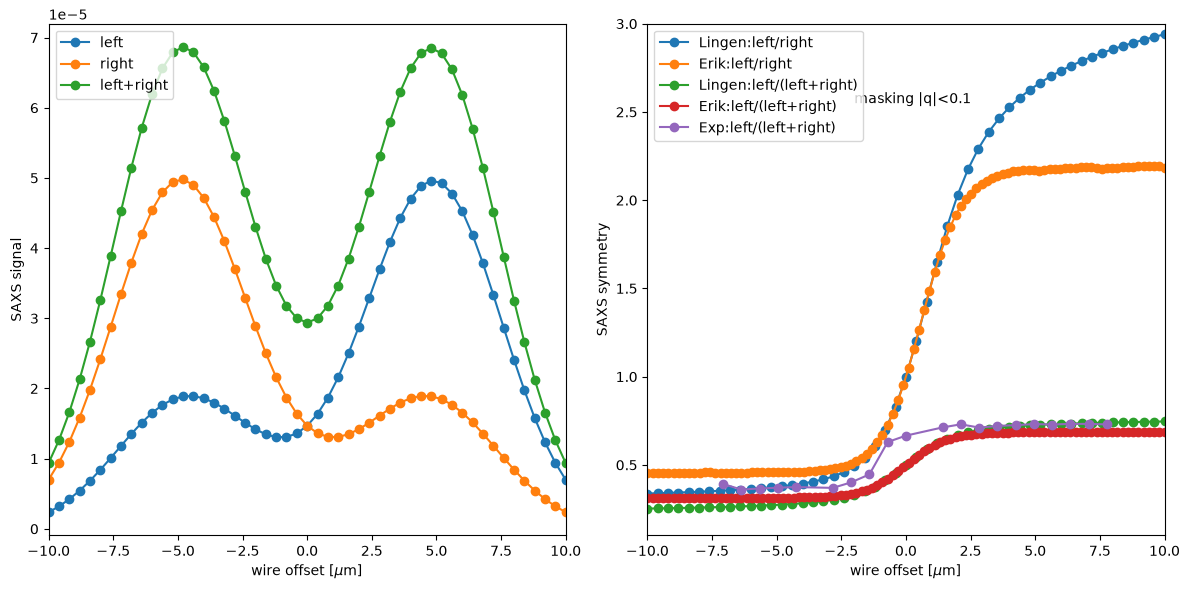

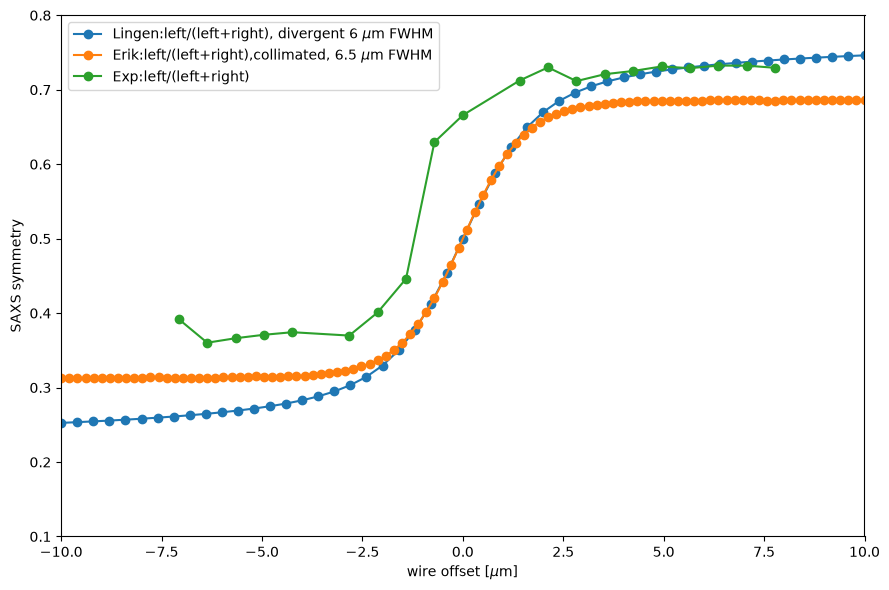

In [12]:
SAXS_asymmetry = np.loadtxt(f'DivSAXS_asymmetry_Mark1300_{waist:0.0f}um.dat') 

data1 = np.load('./Erik/left_div_right.npy')
data2 = np.load('./Erik/left_plus_right.npy')
data3 = np.load('./Erik/pos_grid.npy')
right = data1*data2/(data1+1)
left = data1*right

data4 = np.load('./Erik/motor_positions_um.npy')
data5 = np.load('./Erik/left_div_left_right_exp.npy')

fig = plt.figure(figsize=(12, 6),facecolor="w")
#plt.semilogy(q_GT_528,lineout_IJ_SAXS/np.max(lineout_IJ_SAXS),'-',label='ImageJ:SAXS on detector')
#plt.semilogy(q_GT_528,lineout_SAXS_divergent/np.max(lineout_SAXS_divergent),'--',label=f'Divergent SAXS on detector Source XFEL FWHM = {FWHM_PCIs[0]/1e3:0.3f} $\mu$m')

plt.subplot(1,2,1)
plt.plot(SAXS_asymmetry[:,0]/1e3,SAXS_asymmetry[:,1],'o-',label=f'left')
plt.plot(SAXS_asymmetry[:,0]/1e3,SAXS_asymmetry[:,2],'o-',label=f'right')
plt.plot(SAXS_asymmetry[:,0]/1e3,SAXS_asymmetry[:,1]+SAXS_asymmetry[:,2],'o-',label=f'left+right')

plt.xlim(-10,10)
#plt.ylim(1e-8,5e-4)
#plt.plot(x_pci,np.mean(intensity_detector_pci[2048-1:2048+1,:],axis=0)/np.max(intensity_detector_pci),'--',label='Python:PCI on detector')
#plt.plot(x_pci,np.mean(I4_Fresnel[2048-1:2048+1,:],axis=0)/np.max(I4_Fresnel),'--',label='Lightpipes Fresnel')
#plt.plot(x_pci,np.mean(I4_Forvar[2048-1:2048+1,:],axis=0)/np.max(I4_Forvar),'--',label='Lightpipes Forvar')
#plt.axvline(x = x_peak, color = 'k', label = 'First peak for target thickness')
#plt.axvline(x = 2*np.pi/10e3, color = 'k', label = 'First peak for target thickness')
#plt.text(-0.29, 4e-4, InputParameters, ha='left', va='top',rotation=0, wrap=True)
plt.legend(loc = "upper left")
plt.xlabel(f"wire offset [$\mu$m]")
plt.ylabel("SAXS signal")

plt.subplot(1,2,2)
plt.plot(SAXS_asymmetry[:,0]/1e3,SAXS_asymmetry[:,1]/SAXS_asymmetry[:,2],'o-',label=f'Lingen:left/right')
plt.plot(data3/1e3,data1,'o-',label=f'Erik:left/right')
plt.plot(SAXS_asymmetry[:,0]/1e3,SAXS_asymmetry[:,1]/(SAXS_asymmetry[:,1]+SAXS_asymmetry[:,2]),'o-',label=f'Lingen:left/(left+right)')
#plt.plot(data3/1e3,data2,'o-',label=f'Erik:left/(left+right)')
plt.plot(data3/1e3,left/(left+right),'o-',label=f'Erik:left/(left+right)')

plt.plot(data4,data5,'o-',label=f'Exp:left/(left+right)')

plt.text(-2.0,2.55,f'masking |q|<0.1')
plt.xlim(-10,10)
#plt.ylim(1e-8,5e-4)
#plt.plot(x_pci,np.mean(intensity_detector_pci[2048-1:2048+1,:],axis=0)/np.max(intensity_detector_pci),'--',label='Python:PCI on detector')
#plt.plot(x_pci,np.mean(I4_Fresnel[2048-1:2048+1,:],axis=0)/np.max(I4_Fresnel),'--',label='Lightpipes Fresnel')
#plt.plot(x_pci,np.mean(I4_Forvar[2048-1:2048+1,:],axis=0)/np.max(I4_Forvar),'--',label='Lightpipes Forvar')
#plt.axvline(x = x_peak, color = 'k', label = 'First peak for target thickness')
#plt.axvline(x = 2*np.pi/10e3, color = 'k', label = 'First peak for target thickness')
#plt.text(-0.29, 4e-4, InputParameters, ha='left', va='top',rotation=0, wrap=True)
plt.legend(loc = "upper left")
plt.xlabel(f"wire offset [$\mu$m]")
plt.ylabel("SAXS symmetry")
plt.ylim(0.1,3)


#plt.title('Python: Phase map')
plt.tight_layout()
plt.savefig(f'./SAXS_Asymmetry/DivSAXS_Asymmetry_Mark1300_{waist:0.0f}um.png',dpi=200,bbox_inches='tight')  

fig = plt.figure(figsize=(9, 6),facecolor="w")

#plt.plot(SAXS_asymmetry[:,0]/1e3,SAXS_asymmetry[:,1]/SAXS_asymmetry[:,2],'o-',label=f'left/right')
#plt.plot(data3/1e3,data1,'o-',label=f'Erik:left/right')
plt.plot(SAXS_asymmetry[:,0]/1e3,SAXS_asymmetry[:,1]/(SAXS_asymmetry[:,1]+SAXS_asymmetry[:,2]),'o-',label=f'Lingen:left/(left+right), divergent {waist:0.0f} $\mu$m FWHM')
#plt.plot(data3/1e3,data2,'o-',label=f'Erik:left/(left+right)')
plt.plot(data3/1e3,left/(left+right),'o-',label=f'Erik:left/(left+right),collimated, 6.5 $\mu$m FWHM')

plt.plot(data4,data5,'o-',label=f'Exp:left/(left+right)')

#plt.text(-2.0,2.55,f'masking |q|<0.1')
plt.xlim(-10,10)
#plt.ylim(1e-8,5e-4)
#plt.plot(x_pci,np.mean(intensity_detector_pci[2048-1:2048+1,:],axis=0)/np.max(intensity_detector_pci),'--',label='Python:PCI on detector')
#plt.plot(x_pci,np.mean(I4_Fresnel[2048-1:2048+1,:],axis=0)/np.max(I4_Fresnel),'--',label='Lightpipes Fresnel')
#plt.plot(x_pci,np.mean(I4_Forvar[2048-1:2048+1,:],axis=0)/np.max(I4_Forvar),'--',label='Lightpipes Forvar')
#plt.axvline(x = x_peak, color = 'k', label = 'First peak for target thickness')
#plt.axvline(x = 2*np.pi/10e3, color = 'k', label = 'First peak for target thickness')
#plt.text(-0.29, 4e-4, InputParameters, ha='left', va='top',rotation=0, wrap=True)
plt.legend(loc = "upper left")
plt.xlabel(f"wire offset [$\mu$m]")
plt.ylabel("SAXS symmetry")
plt.ylim(0.1,0.8)


#plt.title('Python: Phase map')
plt.tight_layout()
plt.savefig(f'./SAXS_Asymmetry/DivSAXS_Asymmetry_Mark1300_Exp_{waist:0.0f}um.png',dpi=200,bbox_inches='tight')   

In [13]:
SAXS_asymmetry

array([[-1.00000000e+04,  2.36820256e-06,  7.00775399e-06],
       [-9.60000000e+03,  3.20222352e-06,  9.42733095e-06],
       [-9.20000000e+03,  4.22660605e-06,  1.23754853e-05],
       [-8.80000000e+03,  5.44592149e-06,  1.58529911e-05],
       [-8.40000000e+03,  6.85060058e-06,  1.98175640e-05],
       [-8.00000000e+03,  8.41413384e-06,  2.41767229e-05],
       [-7.60000000e+03,  1.00917960e-05,  2.87855419e-05],
       [-7.20000000e+03,  1.18214975e-05,  3.34509386e-05],
       [-6.80000000e+03,  1.35270393e-05,  3.79430858e-05],
       [-6.40000000e+03,  1.51237800e-05,  4.20135912e-05],
       [-6.00000000e+03,  1.65261790e-05,  4.54185647e-05],
       [-5.60000000e+03,  1.76564154e-05,  4.79438022e-05],
       [-5.20000000e+03,  1.84529272e-05,  4.94284504e-05],
       [-4.80000000e+03,  1.88777121e-05,  4.97835572e-05],
       [-4.40000000e+03,  1.89213515e-05,  4.90025959e-05],
       [-4.00000000e+03,  1.86051220e-05,  4.71622334e-05],
       [-3.60000000e+03,  1.79799936e-05

In [14]:
SAXS_asymmetry = np.loadtxt(f'DivSAXS_asymmetry_Mark1300_{waist:0.0f}um.dat') 

<>:5: SyntaxWarning: invalid escape sequence '\m'
<>:7: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\m'
<>:5: SyntaxWarning: invalid escape sequence '\m'
<>:7: SyntaxWarning: invalid escape sequence '\m'
<>:21: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1889382/772300752.py:5: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(SAXS_asymmetry[:,0]/1e3,SAXS_asymmetry[:,1]/(SAXS_asymmetry[:,1]+SAXS_asymmetry[:,2]),'o-',label=f'left/(left+right), divergent 6 $\mu$m FWHM')
/tmp/ipykernel_1889382/772300752.py:7: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(data3/1e3,left/(left+right),'o-',label=f'left/(left+right),collimated, 6.5 $\mu$m FWHM')
/tmp/ipykernel_1889382/772300752.py:21: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel(f"wire offset [$\mu$m]")


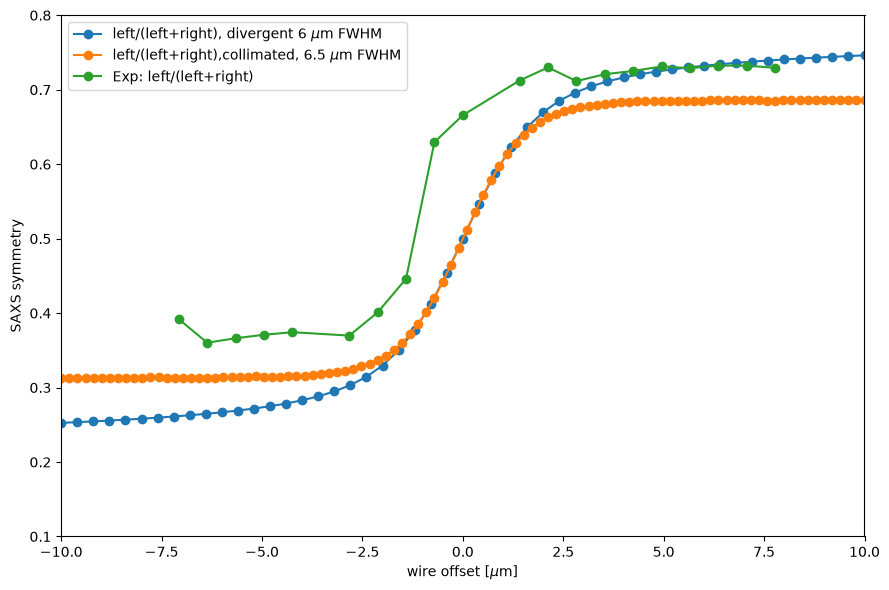

In [15]:
fig = plt.figure(figsize=(9, 6),facecolor="w")

#plt.plot(SAXS_asymmetry[:,0]/1e3,SAXS_asymmetry[:,1]/SAXS_asymmetry[:,2],'o-',label=f'left/right')
#plt.plot(data3/1e3,data1,'o-',label=f'Erik:left/right')
plt.plot(SAXS_asymmetry[:,0]/1e3,SAXS_asymmetry[:,1]/(SAXS_asymmetry[:,1]+SAXS_asymmetry[:,2]),'o-',label=f'left/(left+right), divergent 6 $\mu$m FWHM')
#plt.plot(data3/1e3,data2,'o-',label=f'Erik:left/(left+right)')
plt.plot(data3/1e3,left/(left+right),'o-',label=f'left/(left+right),collimated, 6.5 $\mu$m FWHM')

plt.plot(data4,data5,'o-',label=f'Exp: left/(left+right)')

#plt.text(-2.0,2.55,f'masking |q|<0.1')
plt.xlim(-10,10)
#plt.ylim(1e-8,5e-4)
#plt.plot(x_pci,np.mean(intensity_detector_pci[2048-1:2048+1,:],axis=0)/np.max(intensity_detector_pci),'--',label='Python:PCI on detector')
#plt.plot(x_pci,np.mean(I4_Fresnel[2048-1:2048+1,:],axis=0)/np.max(I4_Fresnel),'--',label='Lightpipes Fresnel')
#plt.plot(x_pci,np.mean(I4_Forvar[2048-1:2048+1,:],axis=0)/np.max(I4_Forvar),'--',label='Lightpipes Forvar')
#plt.axvline(x = x_peak, color = 'k', label = 'First peak for target thickness')
#plt.axvline(x = 2*np.pi/10e3, color = 'k', label = 'First peak for target thickness')
#plt.text(-0.29, 4e-4, InputParameters, ha='left', va='top',rotation=0, wrap=True)
plt.legend(loc = "upper left")
plt.xlabel(f"wire offset [$\mu$m]")
plt.ylabel("SAXS symmetry")
plt.ylim(0.1,0.8)


#plt.title('Python: Phase map')
plt.tight_layout()

In [16]:
data3

array([-10000.     ,  -9797.9795 ,  -9595.96   ,  -9393.939  ,
        -9191.919  ,  -8989.899  ,  -8787.879  ,  -8585.858  ,
        -8383.838  ,  -8181.818  ,  -7979.7974 ,  -7777.7773 ,
        -7575.757  ,  -7373.737  ,  -7171.717  ,  -6969.6963 ,
        -6767.677  ,  -6565.6567 ,  -6363.636  ,  -6161.616  ,
        -5959.5957 ,  -5757.5757 ,  -5555.5557 ,  -5353.535  ,
        -5151.515  ,  -4949.495  ,  -4747.4746 ,  -4545.4546 ,
        -4343.4346 ,  -4141.414  ,  -3939.394  ,  -3737.3738 ,
        -3535.3535 ,  -3333.3333 ,  -3131.313  ,  -2929.293  ,
        -2727.2727 ,  -2525.2524 ,  -2323.2324 ,  -2121.2122 ,
        -1919.1919 ,  -1717.1716 ,  -1515.1515 ,  -1313.1313 ,
        -1111.1111 ,   -909.0909 ,   -707.0707 ,   -505.05054,
         -303.03027,   -101.01007,    101.01013,    303.03033,
          505.05054,    707.07074,    909.09094,   1111.1111 ,
         1313.1313 ,   1515.1516 ,   1717.1718 ,   1919.1919 ,
         2121.2122 ,   2323.2324 ,   2525.2524 ,   2727

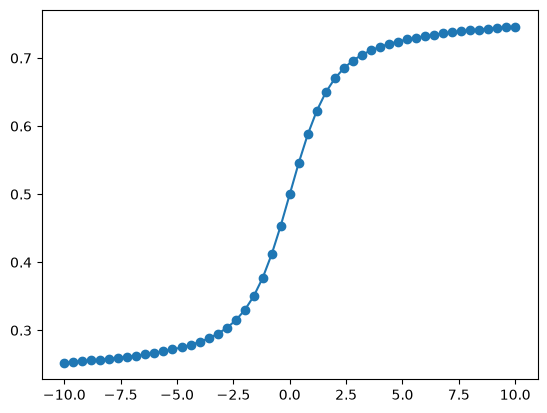

In [17]:
plt.plot(SAXS_asymmetry[:,0]/1e3,SAXS_asymmetry[:,1]/(SAXS_asymmetry[:,1]+SAXS_asymmetry[:,2]),'o-',label=f'left/(left+right)')

In [18]:
lineout_SAXS2 = np.mean(SAXS_divergent[int(N/2-1):int(N/2+1),:],axis=0)

In [19]:
lineout_SAXS2.shape[0]/2


4096.0

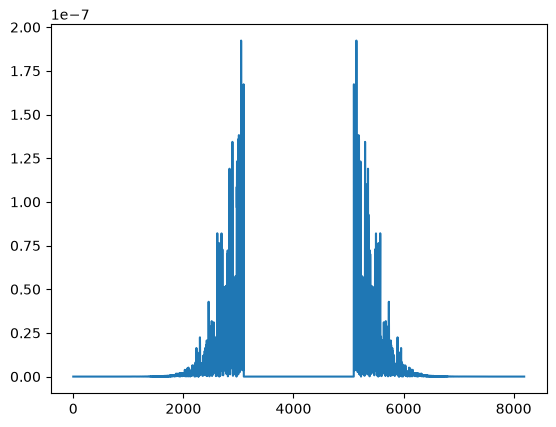

In [20]:
#plt.plot(lineout_SAXS_divergent)
plt.plot(lineout_SAXS2)

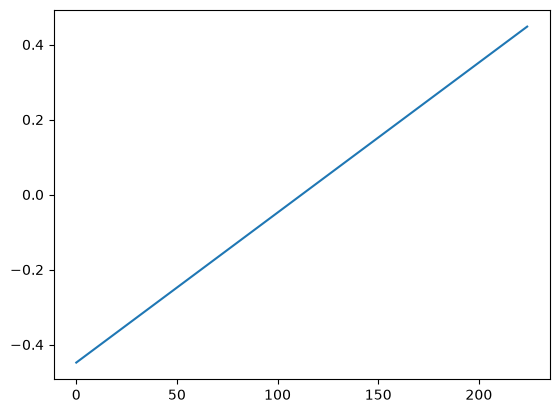

In [21]:
plt.plot(q_GT_528)

<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:4: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1889382/2162145072.py:4: SyntaxWarning: invalid escape sequence '\m'
  plt.semilogy(q_GT_528,lineout_SAXS_divergent/0.02,'-',label=f' {offset/1e3:0.1f} $\mu$m offset')


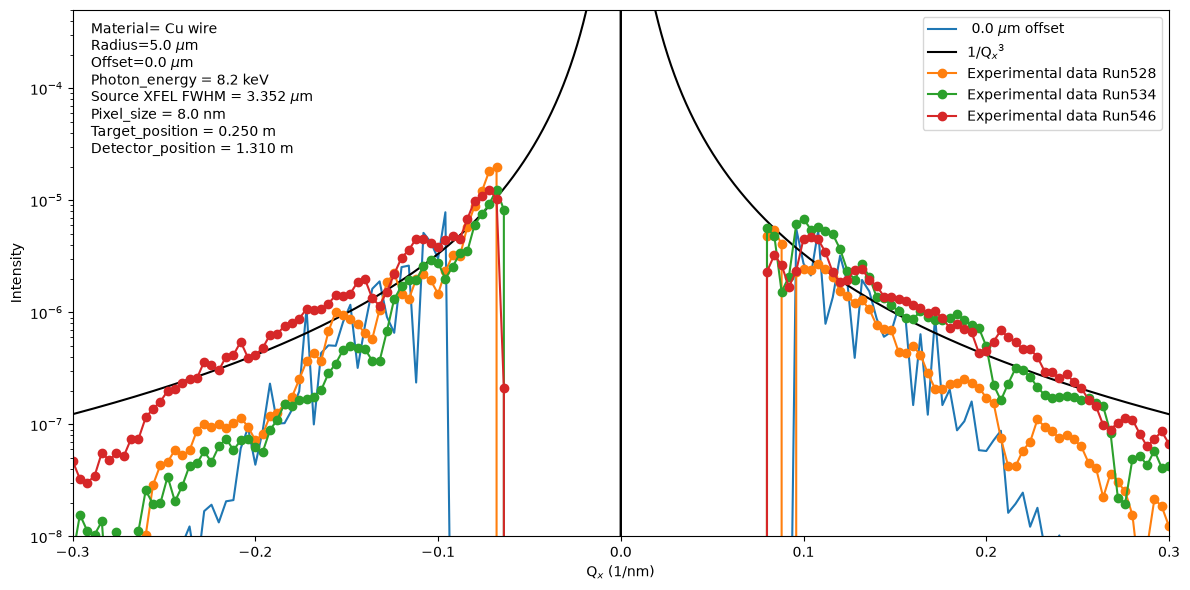

In [22]:
fig = plt.figure(figsize=(12, 6),facecolor="w")
#plt.semilogy(q_GT_528,lineout_IJ_SAXS/np.max(lineout_IJ_SAXS),'-',label='ImageJ:SAXS on detector')
#plt.semilogy(q_GT_528,lineout_SAXS_divergent/np.max(lineout_SAXS_divergent),'--',label=f'Divergent SAXS on detector Source XFEL FWHM = {FWHM_PCIs[0]/1e3:0.3f} $\mu$m')
plt.semilogy(q_GT_528,lineout_SAXS_divergent/0.02,'-',label=f' {offset/1e3:0.1f} $\mu$m offset')
plt.semilogy(k_space, SAXS_theory,'k',label=f'1/Q$_x$$^3$')
plt.semilogy(-k_space, SAXS_theory,'k')
plt.semilogy(q_GT_528,lineout_GT_528/np.max(lineout_GT_528)/50e3,'o-',label='Experimental data Run528')
plt.semilogy(q_GT_534,lineout_GT_534/np.max(lineout_GT_534)/80e3,'o-',label='Experimental data Run534')
plt.semilogy(q_GT_546,lineout_GT_546/np.max(lineout_GT_546)/80e3,'o-',label='Experimental data Run546')
plt.xlim(-0.3,0.3)
plt.ylim(1e-8,5e-4)
#plt.plot(x_pci,np.mean(intensity_detector_pci[2048-1:2048+1,:],axis=0)/np.max(intensity_detector_pci),'--',label='Python:PCI on detector')
#plt.plot(x_pci,np.mean(I4_Fresnel[2048-1:2048+1,:],axis=0)/np.max(I4_Fresnel),'--',label='Lightpipes Fresnel')
#plt.plot(x_pci,np.mean(I4_Forvar[2048-1:2048+1,:],axis=0)/np.max(I4_Forvar),'--',label='Lightpipes Forvar')
#plt.axvline(x = x_peak, color = 'k', label = 'First peak for target thickness')
#plt.axvline(x = 2*np.pi/10e3, color = 'k', label = 'First peak for target thickness')
plt.text(-0.29, 4e-4, InputParameters, ha='left', va='top',rotation=0, wrap=True)
plt.legend(loc = "upper right")
plt.xlabel(f"Q$_x$ (1/nm)")
plt.ylabel("Intensity")
#plt.title('Python: Phase map')
plt.tight_layout()
#plt.savefig(f'./Results/offset{offset/1e3:0.1f}um_{count:02d}DivSAXS_T{12:0.0f}um_Pix{pixel_size_PCI}nm'
#               f'_D{Z_target_PCI/1e9:0.2f}_{Z_detector_PCI/1e9:0.2f}m.png',dpi=200,bbox_inches='tight')   

In [23]:
np.max(lineout_SAXS_divergent)

np.float64(1.5661044252969225e-07)

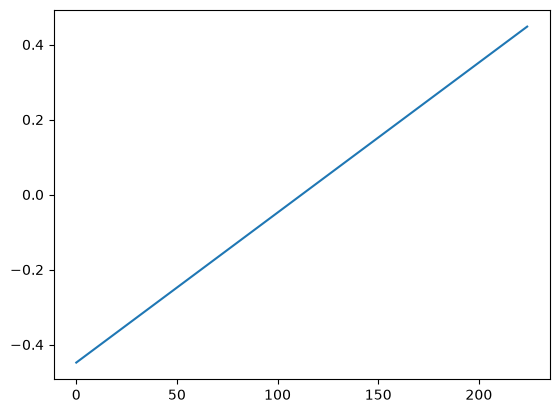

In [24]:
plt.plot(q_GT_528)

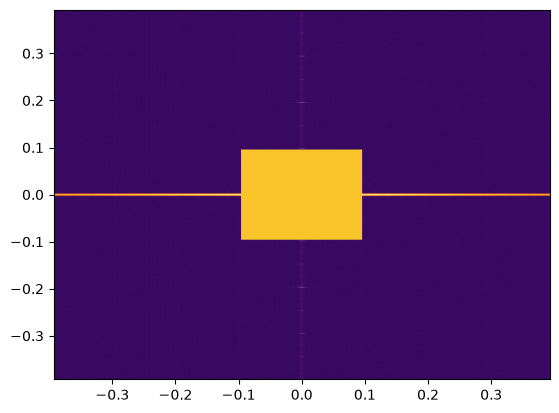

In [25]:
plt.imshow(SAXS_divergent, cmap='inferno', extent=extent_saxs, norm=LogNorm(),aspect='auto')

In [26]:
offset

np.float64(0.0)

<>:2: SyntaxWarning: invalid escape sequence '\m'
<>:2: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1889382/177586220.py:2: SyntaxWarning: invalid escape sequence '\m'
  plt.semilogy(q_GT_528,lineout_SAXS_divergent/np.max(lineout_SAXS_divergent)*2,'--',label=f'Simulated SAXS with 0 $\mu$m wire center offset')


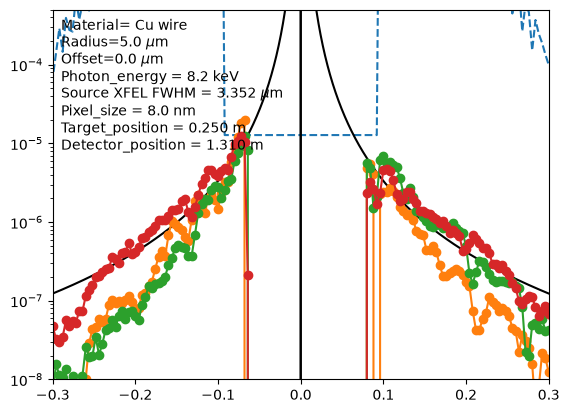

In [27]:
if 1:
    plt.semilogy(q_GT_528,lineout_SAXS_divergent/np.max(lineout_SAXS_divergent)*2,'--',label=f'Simulated SAXS with 0 $\mu$m wire center offset')
    plt.semilogy(k_space, SAXS_theory,'k',label=f'1/Q$_x$$^3$')
    plt.semilogy(-k_space, SAXS_theory,'k')
    plt.semilogy(q_GT_528,lineout_GT_528/np.max(lineout_GT_528)/50e3,'o-',label='Experimental data Run528')
    plt.semilogy(q_GT_534,lineout_GT_534/np.max(lineout_GT_534)/80e3,'o-',label='Experimental data Run534')
    plt.semilogy(q_GT_546,lineout_GT_546/np.max(lineout_GT_546)/80e3,'o-',label='Experimental data Run546')
    plt.xlim(-0.3,0.3)
    plt.ylim(1e-8,5e-4)
    #plt.plot(x_pci,np.mean(intensity_detector_pci[2048-1:2048+1,:],axis=0)/np.max(intensity_detector_pci),'--',label='Python:PCI on detector')
    #plt.plot(x_pci,np.mean(I4_Fresnel[2048-1:2048+1,:],axis=0)/np.max(I4_Fresnel),'--',label='Lightpipes Fresnel')
    #plt.plot(x_pci,np.mean(I4_Forvar[2048-1:2048+1,:],axis=0)/np.max(I4_Forvar),'--',label='Lightpipes Forvar')
    #plt.axvline(x = x_peak, color = 'k', label = 'First peak for target thickness')
    #plt.axvline(x = 2*np.pi/10e3, color = 'k', label = 'First peak for target thickness')
    plt.text(-0.29, 4e-4, InputParameters, ha='left', va='top',rotation=0, wrap=True)

<>:18: SyntaxWarning: invalid escape sequence '\m'
<>:18: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1889382/2215549754.py:18: SyntaxWarning: invalid escape sequence '\m'
  plt.semilogy(q_GT_528,lineout_SAXS_divergent/np.max(lineout_SAXS_divergent)*2,'--',label=f' {offset/1e3:0.1f} $\mu$m offset')


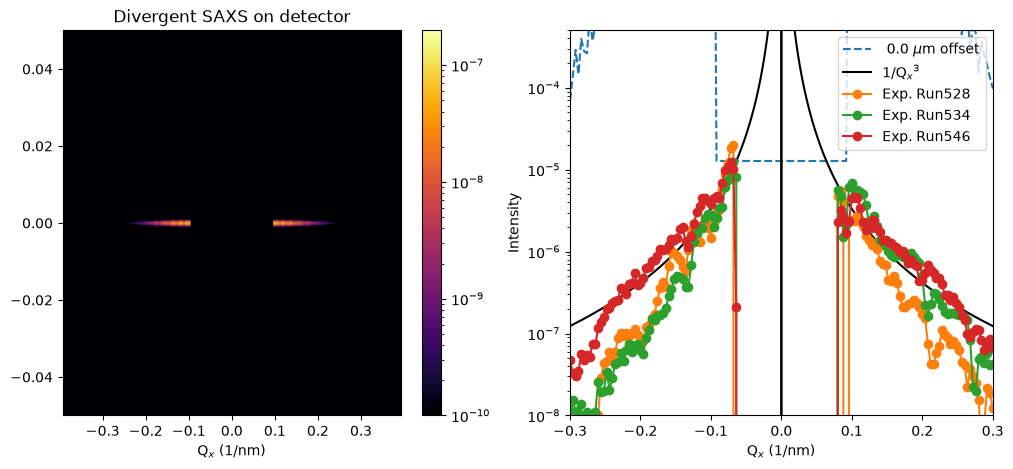

In [28]:
if 1:
    fig = plt.figure(figsize=(12, 5),facecolor="w")
    plt.subplot(1, 2, 1)
    #plt.imshow(intensity_detector, cmap='inferno')
    #plt.imshow(IJ_SAXS, cmap='inferno', extent=extent_saxs,aspect=1)
    plt.imshow(SAXS_divergent, cmap='inferno', extent=extent_saxs, norm=LogNorm(),aspect='auto')
    plt.colorbar()
    #plt.xlim(-size_LP*1e6/2,size_LP*1e6/2)
    plt.ylim(-0.05,0.05)
    #plt.clim(1e-5,1e-20) 
    plt.clim(1e-10,np.max(SAXS_divergent))
    plt.xlabel(f"Q$_x$ (1/nm)")
    #plt.ylabel(f"Q$_y$ (1/nm)")
    plt.title('Divergent SAXS on detector')
    
    plt.subplot(1, 2, 2)
    #plt.semilogy(q_GT_528,lineout_SAXS_divergent/np.max(lineout_SAXS_divergent)*2,'--',label=f'Simulated SAXS with 0 $\mu$m wire center offset')
    plt.semilogy(q_GT_528,lineout_SAXS_divergent/np.max(lineout_SAXS_divergent)*2,'--',label=f' {offset/1e3:0.1f} $\mu$m offset')
    plt.semilogy(k_space, SAXS_theory,'k',label=f'1/Q$_x$$^3$')
    plt.semilogy(-k_space, SAXS_theory,'k')
    plt.semilogy(q_GT_528,lineout_GT_528/np.max(lineout_GT_528)/50e3,'o-',label='Exp. Run528')
    plt.semilogy(q_GT_534,lineout_GT_534/np.max(lineout_GT_534)/80e3,'o-',label='Exp. Run534')
    plt.semilogy(q_GT_546,lineout_GT_546/np.max(lineout_GT_546)/80e3,'o-',label='Exp. Run546')
    plt.xlim(-0.3,0.3)
    plt.ylim(1e-8,5e-4)
    #plt.plot(x_pci,np.mean(intensity_detector_pci[2048-1:2048+1,:],axis=0)/np.max(intensity_detector_pci),'--',label='Python:PCI on detector')
    #plt.plot(x_pci,np.mean(I4_Fresnel[2048-1:2048+1,:],axis=0)/np.max(I4_Fresnel),'--',label='Lightpipes Fresnel')
    #plt.plot(x_pci,np.mean(I4_Forvar[2048-1:2048+1,:],axis=0)/np.max(I4_Forvar),'--',label='Lightpipes Forvar')
    #plt.axvline(x = x_peak, color = 'k', label = 'First peak for target thickness')
    #plt.axvline(x = 2*np.pi/10e3, color = 'k', label = 'First peak for target thickness')
    #plt.text(-0.29, 4e-4, InputParameters, ha='left', va='top',rotation=0, wrap=True)
    plt.legend(loc = "upper right")
    plt.xlabel(f"Q$_x$ (1/nm)")
    plt.ylabel("Intensity")    
    
#    plt.savefig(f'./Results/DivSAXS_offset{offset/1e3:0.1f}um_T{XFEL.FWHM_target:0.0f}um_Pix{pixel_size_PCI}nm'
#                f'_D{Z_target_PCI/1e9:0.2f}_{Z_detector_PCI/1e9:0.2f}m.png',dpi=200,bbox_inches='tight')   

In [29]:
if 0:
    InputParameters = ("Material= Cu wire\n"
                       f"Radius={r_PCI/1e3:0.1f} $\mu$m\n" 
                       f"Photon_energy = {XFEL_photon_energy:0.1f} keV\n"                   
                       f"Source XFEL FWHM = {FWHM_PCI[0]/1e3:0.3f} $\mu$m\n"
                       f"Target XFEL FWHM size = {XFEL.FWHM_target:0.1f} $\mu$m\n"
                       f"Pixel_size = {pixel_size_PCI} nm\n"
                       f"Target_position = {Z_target_PCI/1e9:0.3f} m\n"
                       f"Detector_position = {Z_detector_PCI/1e9:0.3f} m\n")

    fig = plt.figure(figsize=(24/1.5, 20/2.2),facecolor="w")

    plt.subplot(3, 1, 1)
    #plt.imshow(intensity_detector, cmap='inferno')
    #plt.imshow(IJ_SAXS, cmap='inferno', extent=extent_saxs,aspect=1)
    plt.imshow(SAXS_divergent, cmap='inferno', extent=extent_saxs, norm=LogNorm(),aspect='auto')
    plt.colorbar()
    #plt.xlim(-size_LP*1e6/2,size_LP*1e6/2)
    plt.ylim(-0.05,0.05)
    #plt.clim(1e-5,1e-20) 
    plt.clim(1e-10,np.max(SAXS_divergent))
    plt.xlabel(f"Q$_x$ (1/nm)")
    #plt.ylabel(f"Q$_y$ (1/nm)")
    plt.title('Divergent SAXS on detector')


    plt.subplot(3, 1, 2)

    #plt.semilogy(k_space,np.mean(IJ_SAXS[2048-1:2048+1,:],axis=0)/np.max(IJ_SAXS),'--',label='ImageJ:SAXS on detector')
    #plt.semilogy(k_space_IJ,np.mean(IJ_SAXS[2048-5:2048+5,:],axis=0)/np.max(IJ_SAXS),'-',label='ImageJ:SAXS on detector')
    plt.semilogy(k_space,np.mean(SAXS_divergent[int(N/2-5):int(N/2+5),:],axis=0)/np.max(SAXS_divergent),'--',label=f'Divergent SAXS on detector Source XFEL FWHM = {waist:0.0f} $\mu$m')
    #plt.semilogy(k_space,np.mean(SAXS_collimate[int(N/2-5):int(N/2+5),:],axis=0)/np.max(SAXS_collimate),'--',label=f'Collimate SAXS on detector Source XFEL FWHM = {FWHM_PCIs[1]/1e3:0.3f} $\mu$m')
    plt.semilogy(k_space, SAXS_theory,'k',label=f'1/Q$_x$$^3$')
    plt.semilogy(-k_space, SAXS_theory,'k')
    plt.semilogy(q_GT_528,lineout_GT_528/np.max(lineout_GT_528)/50e3,'o-',label='Experimental data Run528')
    plt.semilogy(q_GT_534,lineout_GT_534/np.max(lineout_GT_534)/50e3,'o-',label='Experimental data Run534')
    plt.semilogy(q_GT_546,lineout_GT_546/np.max(lineout_GT_546)/80e3,'o-',label='Experimental data Run546')
    plt.xlim(-0.3,0.3)
    plt.ylim(1e-8,5e-4)
    #plt.plot(x_pci,np.mean(intensity_detector_pci[2048-1:2048+1,:],axis=0)/np.max(intensity_detector_pci),'--',label='Python:PCI on detector')
    #plt.plot(x_pci,np.mean(I4_Fresnel[2048-1:2048+1,:],axis=0)/np.max(I4_Fresnel),'--',label='Lightpipes Fresnel')
    #plt.plot(x_pci,np.mean(I4_Forvar[2048-1:2048+1,:],axis=0)/np.max(I4_Forvar),'--',label='Lightpipes Forvar')
    #plt.axvline(x = x_peak, color = 'k', label = 'First peak for target thickness')
    #plt.axvline(x = 2*np.pi/10e3, color = 'k', label = 'First peak for target thickness')
    plt.text(-0.29, 4e-4, InputParameters, ha='left', va='top',rotation=0, wrap=True)
    plt.legend(loc = "upper right")
    plt.xlabel(f"Q$_x$ (1/nm)")
    plt.ylabel("Intensity")
    #plt.title('Python: Phase map')
    plt.tight_layout()
    
    
    plt.subplot(3, 1, 3)

    plt.semilogy(q_GT_528,lineout_SAXS_divergent/np.max(lineout_SAXS_divergent),'--',label=f'Simulated SAXS with 0 $\mu$m wire center offset')
    plt.semilogy(k_space, SAXS_theory,'k',label=f'1/Q$_x$$^3$')
    plt.semilogy(-k_space, SAXS_theory,'k')
    plt.semilogy(q_GT_528,lineout_GT_528/np.max(lineout_GT_528)/50e3,'o-',label='Experimental data Run528')
    plt.semilogy(q_GT_534,lineout_GT_534/np.max(lineout_GT_534)/80e3,'o-',label='Experimental data Run534')
    plt.semilogy(q_GT_546,lineout_GT_546/np.max(lineout_GT_546)/80e3,'o-',label='Experimental data Run546')
    plt.xlim(-0.3,0.3)
    plt.ylim(1e-8,5e-4)
    #plt.plot(x_pci,np.mean(intensity_detector_pci[2048-1:2048+1,:],axis=0)/np.max(intensity_detector_pci),'--',label='Python:PCI on detector')
    #plt.plot(x_pci,np.mean(I4_Fresnel[2048-1:2048+1,:],axis=0)/np.max(I4_Fresnel),'--',label='Lightpipes Fresnel')
    #plt.plot(x_pci,np.mean(I4_Forvar[2048-1:2048+1,:],axis=0)/np.max(I4_Forvar),'--',label='Lightpipes Forvar')
    #plt.axvline(x = x_peak, color = 'k', label = 'First peak for target thickness')
    #plt.axvline(x = 2*np.pi/10e3, color = 'k', label = 'First peak for target thickness')
    plt.text(-0.29, 4e-4, InputParameters, ha='left', va='top',rotation=0, wrap=True)
    plt.legend(loc = "upper right")
    plt.xlabel(f"Q$_x$ (1/nm)")
    plt.ylabel("Intensity")    
    
#    plt.savefig(f'./Results/DivSAXS_Offset_T{XFEL.FWHM_target:0.0f}um_Pix{pixel_size_PCI}nm'
#                f'_D{Z_target_PCI/1e9:0.2f}_{Z_detector_PCI/1e9:0.2f}m.png',dpi=200,bbox_inches='tight')

<>:3: SyntaxWarning: invalid escape sequence '\m'
<>:5: SyntaxWarning: invalid escape sequence '\m'
<>:6: SyntaxWarning: invalid escape sequence '\m'
<>:31: SyntaxWarning: invalid escape sequence '\m'
<>:55: SyntaxWarning: invalid escape sequence '\m'
<>:3: SyntaxWarning: invalid escape sequence '\m'
<>:5: SyntaxWarning: invalid escape sequence '\m'
<>:6: SyntaxWarning: invalid escape sequence '\m'
<>:31: SyntaxWarning: invalid escape sequence '\m'
<>:55: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1889382/1110921645.py:3: SyntaxWarning: invalid escape sequence '\m'
  f"Radius={r_PCI/1e3:0.1f} $\mu$m\n"
/tmp/ipykernel_1889382/1110921645.py:5: SyntaxWarning: invalid escape sequence '\m'
  f"Source XFEL FWHM = {FWHM_PCI[0]/1e3:0.3f} $\mu$m\n"
/tmp/ipykernel_1889382/1110921645.py:6: SyntaxWarning: invalid escape sequence '\m'
  f"Target XFEL FWHM size = {XFEL.FWHM_target:0.1f} $\mu$m\n"
/tmp/ipykernel_1889382/1110921645.py:31: SyntaxWarning: invalid escape sequence '\m'
  p

In [30]:
if 0:
    SAXS_theory = 1/k_space**(3)/3e8
    InputParameters = ("Material= Cu wire\n"
                       f"Radius={r_PCI/1e3:0.1f} $\mu$m\n" 
                       f"Photon_energy = {XFEL_photon_energy:0.1f} keV\n"                   
                       #f"Source XFEL FWHM = {FWHM_PCI/1e3:0.3f} $\mu$m\n"
                       f"Target XFEL FWHM size = {XFEL.FWHM_target:0.1f} $\mu$m\n"
                       f"Pixel_size = {pixel_size_PCI} nm\n"
                       f"Target_position = {Z_target_PCI/1e9:0.3f} m\n"
                       f"Detector_position = {Z_detector_PCI/1e9:0.3f} m\n")

    fig = plt.figure(figsize=(24/1.5, 20/2.2),facecolor="w")


    plt.subplot(2, 3, 1)
    #plt.imshow(intensity_detector, cmap='inferno')
    #plt.imshow(IJ_SAXS, cmap='inferno', extent=extent_saxs,aspect=1)
    plt.imshow(IJ_SAXS, cmap='inferno', extent=extent_saxs, norm=LogNorm(),aspect='auto')
    plt.colorbar()
    #plt.xlim(-size_LP*1e6/2,size_LP*1e6/2)
    plt.ylim(-0.05,0.05)
    #plt.clim(1e-5,1e-20) 
    #plt.clim(-10,10)
    plt.xlabel(f"Q$_x$ (1/nm)")
    plt.ylabel(f"Q$_y$ (1/nm)")
    plt.title('ImageJ SAXS on detector')

    plt.subplot(2, 3, 2)
    #plt.imshow(intensity_detector, cmap='inferno')
    #plt.imshow(IJ_SAXS, cmap='inferno', extent=extent_saxs,aspect=1)
    plt.imshow(SAXS_divergent, cmap='inferno', extent=extent_saxs, norm=LogNorm(),aspect='auto')
    plt.colorbar()
    #plt.xlim(-size_LP*1e6/2,size_LP*1e6/2)
    plt.ylim(-0.05,0.05)
    #plt.clim(1e-5,1e-20) 
    plt.clim(1e-10,np.max(SAXS_divergent))
    plt.xlabel(f"Q$_x$ (1/nm)")
    #plt.ylabel(f"Q$_y$ (1/nm)")
    plt.title('Divergent SAXS on detector')

    plt.subplot(2, 3, 3)
    #plt.imshow(intensity_detector, cmap='inferno')
    #plt.imshow(IJ_PCI, cmap='inferno', extent=extent_saxs,aspect=1)
    plt.imshow(SAXS_collimate, cmap='inferno', extent=extent_saxs, norm=LogNorm(),aspect='auto')
    #plt.xlim(-size_LP*1e6/2,size_LP*1e6/2)
    plt.ylim(-0.05,0.05)
    plt.colorbar()
    plt.xlabel(f"Q$_x$ (1/nm)")
    #plt.ylabel(f"Q$_y$ (1/nm)")
    #plt.clim(1e-5,1e-20) 
    plt.clim(1e-10,np.max(SAXS_collimate))
    plt.title('Collimated SAXS on detector')

    plt.subplot(2, 1, 2)


    plt.semilogy(q_GT_528,lineout_IJ_SAXS/np.max(lineout_IJ_SAXS),'-',label='ImageJ:SAXS on detector')
    plt.semilogy(q_GT_528,lineout_SAXS_divergent/np.max(lineout_SAXS_divergent),'--',label=f'Divergent SAXS on detector Source XFEL FWHM = {FWHM_PCIs[0]/1e3:0.3f} $\mu$m')
    plt.semilogy(q_GT_528,lineout_SAXS_collimate/np.max(lineout_SAXS_collimate),'--',label=f'Collimate SAXS on detector Source XFEL FWHM = {FWHM_PCIs[1]/1e3:0.3f} $\mu$m')
    plt.semilogy(k_space, SAXS_theory,'k',label=f'1/Q$_x$$^3$')
    plt.semilogy(-k_space, SAXS_theory,'k')
    plt.semilogy(q_GT_528,lineout_GT_528/np.max(lineout_GT_528)/50e3,'o-',label='Experimental data Run528')
    plt.semilogy(q_GT_534,lineout_GT_534/np.max(lineout_GT_534)/50e3,'o-',label='Experimental data Run534')
    plt.semilogy(q_GT_546,lineout_GT_546/np.max(lineout_GT_546)/80e3,'o-',label='Experimental data Run546')
    plt.xlim(-0.3,0.3)
    plt.ylim(1e-8,5e-4)
    #plt.plot(x_pci,np.mean(intensity_detector_pci[2048-1:2048+1,:],axis=0)/np.max(intensity_detector_pci),'--',label='Python:PCI on detector')
    #plt.plot(x_pci,np.mean(I4_Fresnel[2048-1:2048+1,:],axis=0)/np.max(I4_Fresnel),'--',label='Lightpipes Fresnel')
    #plt.plot(x_pci,np.mean(I4_Forvar[2048-1:2048+1,:],axis=0)/np.max(I4_Forvar),'--',label='Lightpipes Forvar')
    #plt.axvline(x = x_peak, color = 'k', label = 'First peak for target thickness')
    #plt.axvline(x = 2*np.pi/10e3, color = 'k', label = 'First peak for target thickness')
    plt.text(-0.29, 4e-4, InputParameters, ha='left', va='top',rotation=0, wrap=True)
    plt.legend(loc = "upper right")
    plt.xlabel(f"Q$_x$ (1/nm)")
    plt.ylabel("Intensity")
    #plt.title('Python: Phase map')
    #plt.tight_layout()
#    plt.savefig(f'./Results/Interpolate_SAXS_DivergentCollimate_T{XFEL.FWHM_target:0.0f}um_Pix{pixel_size_PCI}nm'
#                f'_D{Z_target_PCI/1e9:0.2f}_{Z_detector_PCI/1e9:0.2f}m.png',dpi=200,bbox_inches='tight')

<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:7: SyntaxWarning: invalid escape sequence '\m'
<>:58: SyntaxWarning: invalid escape sequence '\m'
<>:59: SyntaxWarning: invalid escape sequence '\m'
<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:7: SyntaxWarning: invalid escape sequence '\m'
<>:58: SyntaxWarning: invalid escape sequence '\m'
<>:59: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1889382/1118525821.py:4: SyntaxWarning: invalid escape sequence '\m'
  f"Radius={r_PCI/1e3:0.1f} $\mu$m\n"
/tmp/ipykernel_1889382/1118525821.py:7: SyntaxWarning: invalid escape sequence '\m'
  f"Target XFEL FWHM size = {XFEL.FWHM_target:0.1f} $\mu$m\n"
/tmp/ipykernel_1889382/1118525821.py:58: SyntaxWarning: invalid escape sequence '\m'
  plt.semilogy(q_GT_528,lineout_SAXS_divergent/np.max(lineout_SAXS_divergent),'--',label=f'Divergent SAXS on detector Source XFEL FWHM = {FWHM_PCIs[0]/1e3:0.3f} $\mu$m')
/tmp/ipykernel_1889382/1118525821.py:59: SyntaxWarning: invalid escape se

In [31]:
np.mean(SAXS_divergent[2048-1:2048+1,:],axis=0).shape

(8192,)

<>:4: SyntaxWarning: invalid escape sequence '\m'
<>:4: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1889382/1772629634.py:4: SyntaxWarning: invalid escape sequence '\m'
  plt.semilogy(q_GT_528,lineout_SAXS_divergent/np.max(lineout_SAXS_divergent),'--',label=f'Simulated SAXS with 0 $\mu$m wire center offset')


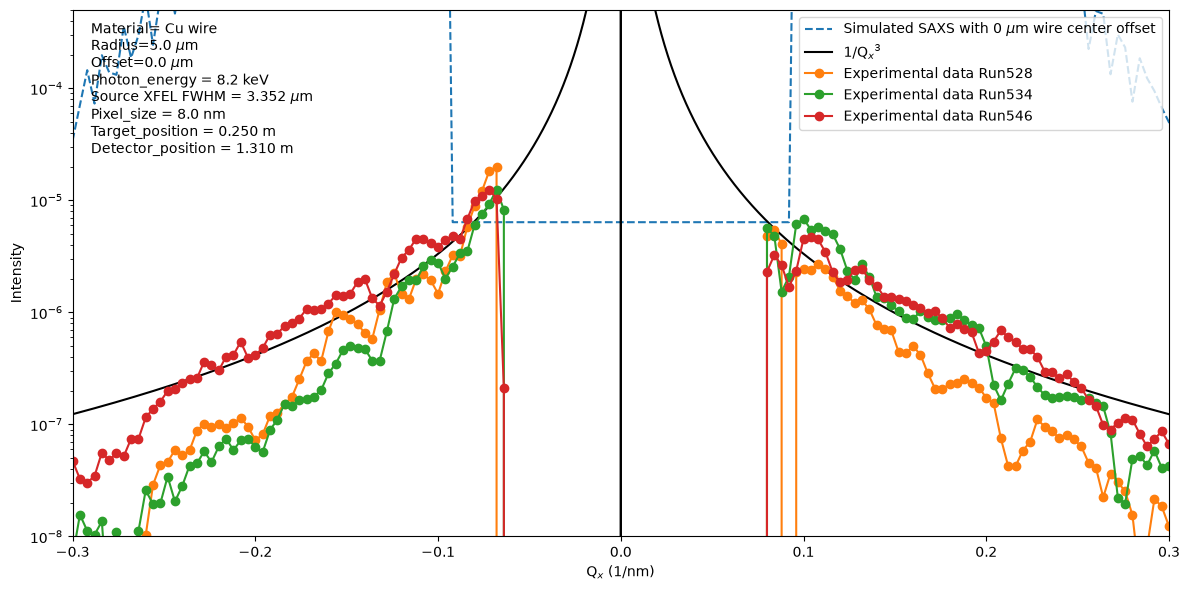

In [32]:
fig = plt.figure(figsize=(12, 6),facecolor="w")
#plt.semilogy(q_GT_528,lineout_IJ_SAXS/np.max(lineout_IJ_SAXS),'-',label='ImageJ:SAXS on detector')
#plt.semilogy(q_GT_528,lineout_SAXS_divergent/np.max(lineout_SAXS_divergent),'--',label=f'Divergent SAXS on detector Source XFEL FWHM = {FWHM_PCIs[0]/1e3:0.3f} $\mu$m')
plt.semilogy(q_GT_528,lineout_SAXS_divergent/np.max(lineout_SAXS_divergent),'--',label=f'Simulated SAXS with 0 $\mu$m wire center offset')
plt.semilogy(k_space, SAXS_theory,'k',label=f'1/Q$_x$$^3$')
plt.semilogy(-k_space, SAXS_theory,'k')
plt.semilogy(q_GT_528,lineout_GT_528/np.max(lineout_GT_528)/50e3,'o-',label='Experimental data Run528')
plt.semilogy(q_GT_534,lineout_GT_534/np.max(lineout_GT_534)/80e3,'o-',label='Experimental data Run534')
plt.semilogy(q_GT_546,lineout_GT_546/np.max(lineout_GT_546)/80e3,'o-',label='Experimental data Run546')
plt.xlim(-0.3,0.3)
plt.ylim(1e-8,5e-4)
#plt.plot(x_pci,np.mean(intensity_detector_pci[2048-1:2048+1,:],axis=0)/np.max(intensity_detector_pci),'--',label='Python:PCI on detector')
#plt.plot(x_pci,np.mean(I4_Fresnel[2048-1:2048+1,:],axis=0)/np.max(I4_Fresnel),'--',label='Lightpipes Fresnel')
#plt.plot(x_pci,np.mean(I4_Forvar[2048-1:2048+1,:],axis=0)/np.max(I4_Forvar),'--',label='Lightpipes Forvar')
#plt.axvline(x = x_peak, color = 'k', label = 'First peak for target thickness')
#plt.axvline(x = 2*np.pi/10e3, color = 'k', label = 'First peak for target thickness')
plt.text(-0.29, 4e-4, InputParameters, ha='left', va='top',rotation=0, wrap=True)
plt.legend(loc = "upper right")
plt.xlabel(f"Q$_x$ (1/nm)")
plt.ylabel("Intensity")
#plt.title('Python: Phase map')
plt.tight_layout()
#plt.savefig(f'./Results/0umoffset_SAXS_T{XFEL.FWHM_target:0.0f}um_Pix{pixel_size_PCI}nm'
#            f'_D{Z_target_PCI/1e9:0.2f}_{Z_detector_PCI/1e9:0.2f}m.png',dpi=200,bbox_inches='tight')

In [33]:
fig = plt.figure(figsize=(11, 6),facecolor="w")
#plt.semilogy(q_GT_528,lineout_IJ_SAXS/np.max(lineout_IJ_SAXS),'-',label='ImageJ:SAXS on detector')
#plt.semilogy(q_GT_528,lineout_SAXS_divergent/np.max(lineout_SAXS_divergent),'--',label=f'Divergent SAXS on detector Source XFEL FWHM = {FWHM_PCIs[0]/1e3:0.3f} $\mu$m')
plt.semilogy(q_GT_528,lineout_SAXS_collimate/np.max(lineout_SAXS_collimate),'o-',label=f'Simulated SAXS')
plt.semilogy(k_space, SAXS_theory,'k',label=f'1/Q$_x$$^3$')
plt.semilogy(-k_space, SAXS_theory,'k')

plt.semilogy(q_GT_546,lineout_GT_546/np.max(lineout_GT_546)/100e3,'o-',label='Experimental data Run546')
plt.xlim(-0.3,0.3)
plt.ylim(1e-8,5e-4)
#plt.plot(x_pci,np.mean(intensity_detector_pci[2048-1:2048+1,:],axis=0)/np.max(intensity_detector_pci),'--',label='Python:PCI on detector')
#plt.plot(x_pci,np.mean(I4_Fresnel[2048-1:2048+1,:],axis=0)/np.max(I4_Fresnel),'--',label='Lightpipes Fresnel')
#plt.plot(x_pci,np.mean(I4_Forvar[2048-1:2048+1,:],axis=0)/np.max(I4_Forvar),'--',label='Lightpipes Forvar')
#plt.axvline(x = x_peak, color = 'k', label = 'First peak for target thickness')
#plt.axvline(x = 2*np.pi/10e3, color = 'k', label = 'First peak for target thickness')
plt.text(-0.29, 4e-4, InputParameters, ha='left', va='top',rotation=0, wrap=True)
plt.legend(loc = "upper right")
plt.xlabel(f"Q$_x$ (1/nm)")
plt.ylabel("Intensity")
#plt.xlim(0.1,0.3)
#plt.title('Python: Phase map')
plt.tight_layout()
plt.show()
#plt.savefig(f'./Results/Run546_SAXS_T{XFEL.FWHM_target:0.0f}um_Pix{pixel_size_PCI}nm'
#            f'_D{Z_target_PCI/1e9:0.2f}_{Z_detector_PCI/1e9:0.2f}m.png',dpi=200,bbox_inches='tight')

<Figure size 1100x600 with 0 Axes>

In [ ]:
fig = plt.figure(figsize=(11, 6),facecolor="w")
#plt.semilogy(q_GT_528,lineout_IJ_SAXS/np.max(lineout_IJ_SAXS),'-',label='ImageJ:SAXS on detector')
#plt.semilogy(q_GT_528,lineout_SAXS_divergent/np.max(lineout_SAXS_divergent),'--',label=f'Divergent SAXS on detector Source XFEL FWHM = {FWHM_PCIs[0]/1e3:0.3f} $\mu$m')
plt.semilogy(q_GT_528,lineout_SAXS_collimate/np.max(lineout_SAXS_collimate),'o-',label=f'Simulated SAXS')
plt.semilogy(k_space, SAXS_theory,'k',label=f'1/Q$_x$$^3$')
plt.semilogy(-k_space, SAXS_theory,'k')

plt.semilogy(q_GT_546,lineout_GT_546/np.max(lineout_GT_546)/100e3,'o-',label='Experimental data Run546')
plt.xlim(0.1,0.1+6e-3*5)
plt.ylim(1e-6,1e-5)
#plt.plot(x_pci,np.mean(intensity_detector_pci[2048-1:2048+1,:],axis=0)/np.max(intensity_detector_pci),'--',label='Python:PCI on detector')
#plt.plot(x_pci,np.mean(I4_Fresnel[2048-1:2048+1,:],axis=0)/np.max(I4_Fresnel),'--',label='Lightpipes Fresnel')
#plt.plot(x_pci,np.mean(I4_Forvar[2048-1:2048+1,:],axis=0)/np.max(I4_Forvar),'--',label='Lightpipes Forvar')
#plt.axvline(x = x_peak, color = 'k', label = 'First peak for target thickness')
#plt.axvline(x = 2*np.pi/10e3, color = 'k', label = 'First peak for target thickness')
#plt.text(-0.29, 4e-4, InputParameters, ha='left', va='top',rotation=0, wrap=True)
plt.legend(loc = "upper right")
plt.xlabel(f"Q$_x$ (1/nm)")
plt.ylabel("Intensity")
#plt.xlim(0.1,0.3)
#plt.title('Python: Phase map')
plt.tight_layout()
plt.show()
#plt.savefig(f'./Results/Run546_SAXS_T{XFEL.FWHM_target:0.0f}um_Pix{pixel_size_PCI}nm'
#            f'_D{Z_target_PCI/1e9:0.2f}_{Z_detector_PCI/1e9:0.2f}m.png',dpi=200,bbox_inches='tight')